In [1]:
import json
import os
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# Your own datasets mount under /kaggle/input/datasets/<owner>/<slug>.
# Discover rather than hardcode - the same fix Week 6 needed.
def resolve(slug, root=Path("/kaggle/input"), max_depth=3):
    for depth in range(1, max_depth + 1):
        hits = [p for p in root.glob("/".join(["*"] * (depth - 1) + [slug]))
                if p.is_dir()]
        if hits:
            return hits[0]
    raise FileNotFoundError(f"{slug} not attached - Add Data first")


EYEQ = resolve("eyeq-512-full") / "eyeq_512"
SPLITS = resolve("retina-results") / "manifest_split.csv"
EXTERNAL = resolve("retina-external-512")
print(EYEQ, SPLITS, EXTERNAL, sep="\n")

WORK = Path("/kaggle/working")
DEGRADED = WORK / "degraded"
FIGURES = WORK / "figures"
for d in (DEGRADED, FIGURES):
    d.mkdir(exist_ok=True)

DEFECTS = ["underexposed", "defocus", "obstruction", "off_centre"]
SEED = 42
rng = np.random.default_rng(SEED)

print(sorted(p.name for p in EXTERNAL.iterdir()))

/kaggle/input/datasets/izuchukwuoruche/eyeq-512-full/eyeq_512
/kaggle/input/datasets/izuchukwuoruche/retina-results/manifest_split.csv
/kaggle/input/datasets/izuchukwuoruche/retina-external-512
['external_512', 'manifest_external_512.csv']


In [2]:
df = pd.read_csv(SPLITS)

source = df[(df.split == "train") & (df.quality == 0)]
print(f"{len(source):,} Good training images available")
print(f"patients: {source.patient_id.nunique():,}")


def load(stem):
    img = cv2.imread(str(EYEQ / f"{stem}.png"))
    if img is None:
        raise IOError(f"cannot read {stem}")
    return img          # BGR, 512x512

6,798 Good training images available
patients: 4,365


In [3]:
def _fov_mask(img, tol=7):
    """Boolean mask of the circular retina, excluding black padding."""
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) > tol


def underexpose(img, sev):
    """Reduced illumination. Mimics a small pupil or weak flash.

    Gamma > 1 darkens midtones more than shadows, which is how real
    underexposure behaves - a linear scale looks obviously fake.
    """
    if sev <= 0:
        return img
    # ranges chosen so the retina stays above the FOV mask threshold even
    # at severity 1.0 - darken harder and crop_fov sees a blank image
    gamma = 1.0 + 1.6 * sev                  # 1.0 -> 2.6
    scale = 1.0 - 0.45 * sev                 # 1.0 -> 0.55
    lut = np.array([((i / 255.0) ** gamma) * 255.0 * scale
                    for i in range(256)], dtype=np.uint8)
    return cv2.LUT(img, lut)


def defocus(img, sev):
    """Out-of-focus blur. Gaussian is a fair approximation at this scale.

    The curve is tuned for the resolution the MODEL sees, not the 512 px
    file on disk. Downscaling 512 -> 224 is itself a low-pass filter: it
    strips about as much fine detail on its own as a sigma 1.0 blur. So
    any sigma much below 1.0 applied here is erased by the resize, and
    what reaches the model is pixel-wise indistinguishable from a clean
    image - while still carrying a "defocus, severity 0.25" label. That
    is a label-noise generator, not a hard example.

    Hence the 0.60 floor: the mildest severity actually sampled (0.25)
    has to survive the resize. The 1.7 exponent then spreads the rest of
    the range evenly rather than saturating near the top. A linear ramp
    to sigma 8 fails the opposite way - it destroys all detail by
    severity 0.25, so every level above that is identical.
    """
    if sev <= 0:
        return img
    sigma = 0.60 + 3.6 * (sev ** 1.7)        # 0.25 -> 0.94,  1.0 -> 4.20 px
    k = int(2 * round(3 * sigma) + 1)        # kernel must be odd
    return cv2.GaussianBlur(img, (k, k), sigma)


def obstruction(img, sev):
    """Eyelid intruding from the top edge, plus lashes at higher severity.

    Clipped to the field of view so it does not spill onto the black
    padding, which would be an obvious giveaway rather than a defect.
    """
    if sev <= 0:
        return img
    out = img.copy()
    h, w = img.shape[:2]
    mask = _fov_mask(img)

    # dark ellipse descending from the top
    depth = int(h * (0.12 + 0.48 * sev))
    lid = np.zeros((h, w), np.uint8)
    cv2.ellipse(lid, (w // 2, depth - int(h * 0.35)),
                (int(w * 0.75), int(h * 0.45)), 0, 0, 360, 255, -1)
    lid = (lid > 0) & mask
    out[lid] = (out[lid] * (1.0 - 0.85 * sev)).astype(np.uint8)

    # lashes appear once the lid is well into frame
    if sev > 0.45:
        for _ in range(int(14 * sev)):
            x = int(rng.uniform(w * 0.15, w * 0.85))
            length = int(h * rng.uniform(0.05, 0.16) * sev)
            cv2.line(out, (x, max(depth - 12, 0)), (x + int(rng.uniform(-14, 14)),
                     max(depth - 12, 0) + length), (12, 12, 12),
                     thickness=max(1, int(3 * sev)))
    return out


def off_centre(img, sev):
    """Translate the field of view so the disc and macula drift off frame.

    The shift is rounded to whole pixels, and this is not cosmetic.
    warpAffine resamples, and a fractional offset makes it interpolate
    between neighbouring pixels - bilinear interpolation is a low-pass
    filter, so a sub-pixel shift silently blurs the image. The amount
    depends on the fractional part of a RANDOM angle, so every
    off-centre image would carry a different, meaningless amount of
    blur. That contaminates the defocus label as well as this one.
    An integer shift moves pixels without touching their values.
    """
    if sev <= 0:
        return img
    h, w = img.shape[:2]
    angle = rng.uniform(0, 2 * np.pi)
    dist = 0.42 * sev * w
    M = np.float32([[1, 0, round(dist * np.cos(angle))],
                    [0, 1, round(dist * np.sin(angle))]])
    return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_NEAREST,
                          borderValue=(0, 0, 0))


DEGRADE_FN = {
    "underexposed": underexpose,
    "defocus": defocus,
    "obstruction": obstruction,
    "off_centre": off_centre,
}

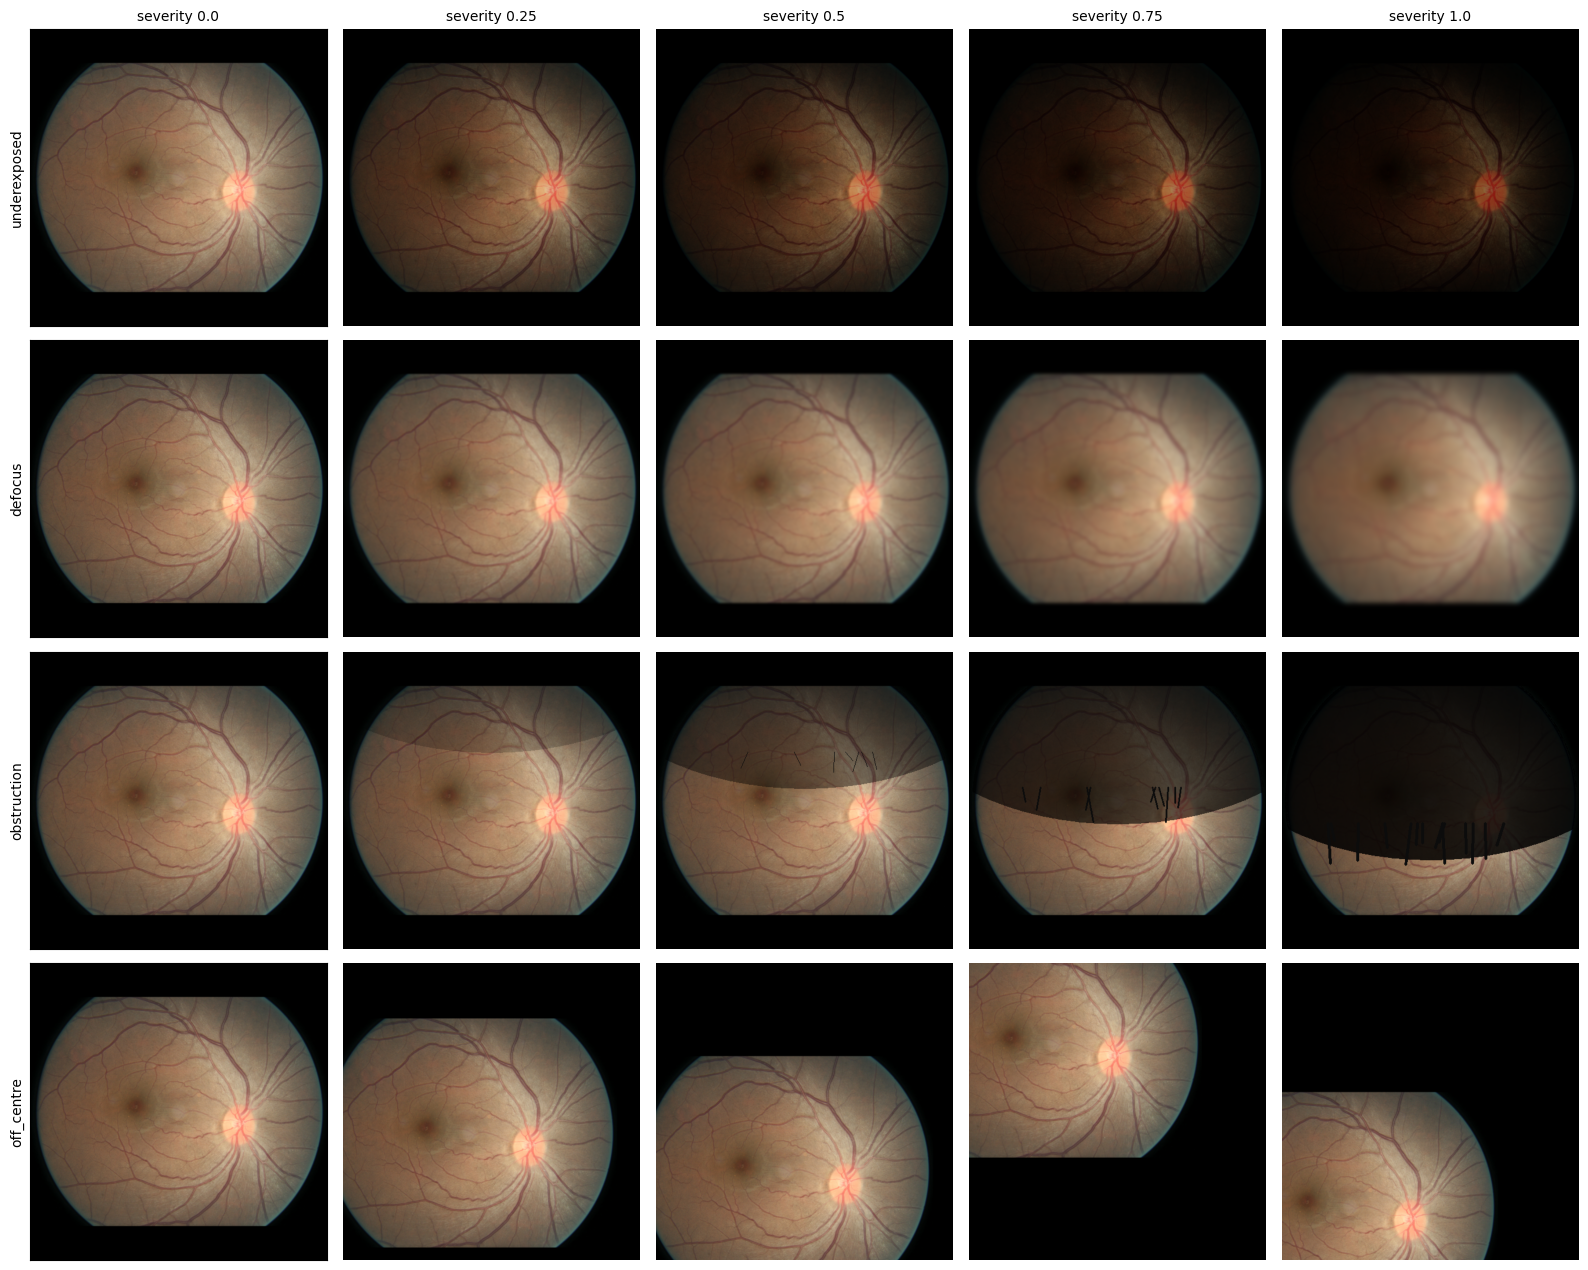

In [4]:
img = load(source.stem.iloc[0])
levels = [0.0, 0.25, 0.5, 0.75, 1.0]

fig, axes = plt.subplots(len(DEFECTS), len(levels),
                         figsize=(3.2 * len(levels), 3.2 * len(DEFECTS)))
for r, name in enumerate(DEFECTS):
    for c, sev in enumerate(levels):
        out = DEGRADE_FN[name](img, sev)
        axes[r, c].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(f"severity {sev}", fontsize=10)
    axes[r, 0].set_ylabel(name)
    axes[r, 0].axis("on")
    axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])

plt.tight_layout()
plt.savefig(FIGURES / "degradation_grid.png", dpi=150)
plt.show()

In [5]:
# does the mildest severity we actually sample survive the resize?
import numpy as np
g0 = cv2.resize(load(source.stem.iloc[0]), (224, 224), interpolation=cv2.INTER_AREA)
for s in [0.25, 0.5, 1.0]:
    gs = cv2.resize(defocus(load(source.stem.iloc[0]), s), (224, 224),
                    interpolation=cv2.INTER_AREA)
    lv  = cv2.Laplacian(cv2.cvtColor(gs, cv2.COLOR_BGR2GRAY),
                        cv2.CV_32F).var()
    lv0 = cv2.Laplacian(cv2.cvtColor(g0, cv2.COLOR_BGR2GRAY),
                        cv2.CV_32F).var()
    print(f"sev {s:4.2f}  retains {100 * lv / lv0:5.1f}% of clean detail at 224")
# expect roughly 55% / 20% / 2% - each level clearly apart from the next.
# anything above ~80% at sev 0.25 means the resize is eating your mild end.

sev 0.25  retains  48.8% of clean detail at 224
sev 0.50  retains  19.0% of clean detail at 224
sev 1.00  retains   2.7% of clean detail at 224


In [6]:
def features(img):
    """img: RGB uint8, 512x512 from the cached dataset. Returns 8 scalars."""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = gray > 7                      # retina only, not the black padding
    f = {}

    # ---- SHARPNESS ----------------------------------------------------
    # Laplacian variance: high on crisp edges, near zero on blur.
    # The classic blur detector and still hard to beat.
    f["lap_var"] = float(cv2.Laplacian(gray, cv2.CV_64F).var())

    # Tenengrad: gradient energy. A second opinion on focus that responds
    # differently to sensor noise than the Laplacian does.
    gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    f["tenengrad"] = float(np.mean(gx ** 2 + gy ** 2))

    # ---- EXPOSURE -----------------------------------------------------
    v = gray[mask]
    f["mean"] = float(v.mean())
    f["std"] = float(v.std())
    f["clip_low"] = float((v < 15).mean())       # crushed shadows
    f["clip_high"] = float((v > 240).mean())     # blown highlights

    # ---- ILLUMINATION EVENNESS ----------------------------------------
    # An eyelid or bad flash angle darkens one region. Compare quadrant
    # means; uneven lighting shows as high relative spread.
    h, w = gray.shape
    quads = [gray[:h // 2, :w // 2], gray[:h // 2, w // 2:],
             gray[h // 2:, :w // 2], gray[h // 2:, w // 2:]]
    qm = [q[q > 7].mean() if (q > 7).any() else 0.0 for q in quads]
    f["illum_cv"] = float(np.std(qm) / (np.mean(qm) + 1e-6))

    # ---- COLOUR -------------------------------------------------------
    # The green channel carries most retinal vessel contrast, so its spread
    # is a cheap proxy for structural visibility.
    f["green_std"] = float(img[:, :, 1][mask].std())

    return f

rows = []
for stem_ in source.stem.head(30):
    base = load(stem_)
    for name in DEFECTS:
        for sev in [0.0, 0.25, 0.5, 0.75, 1.0]:
            f = features(cv2.cvtColor(DEGRADE_FN[name](base, sev),
                                      cv2.COLOR_BGR2RGB))
            rows.append({"defect": name, "sev": sev, **f})

probe = pd.DataFrame(rows)

print("mean lap_var by defect and severity (blur should fall)")
print(probe.pivot_table(index="defect", columns="sev",
                        values="lap_var").round(1))
print("\nmean brightness (underexposure should fall)")
print(probe.pivot_table(index="defect", columns="sev",
                        values="mean").round(1))
print("\nmean illum_cv (obstruction should rise)")
print(probe.pivot_table(index="defect", columns="sev",
                        values="illum_cv").round(3))

mean lap_var by defect and severity (blur should fall)
sev           0.00  0.25  0.50  0.75   1.00
defect                                     
defocus       75.7   8.9   3.1   1.7    1.4
obstruction   75.7  69.5  96.0  94.0  111.2
off_centre    75.7  63.7  53.6  44.4   37.0
underexposed  75.7  45.4  26.7  15.6    9.0

mean brightness (underexposure should fall)
sev            0.00   0.25   0.50   0.75   1.00
defect                                         
defocus       105.8  105.1  104.3  103.2  101.8
obstruction   105.8  100.5   87.8   66.5   38.0
off_centre    105.8  106.6  108.4  109.9  109.3
underexposed  105.8   70.2   47.3   32.9   24.2

mean illum_cv (obstruction should rise)
sev            0.00   0.25   0.50   0.75   1.00
defect                                         
defocus       0.092  0.092  0.091  0.091  0.091
obstruction   0.092  0.108  0.225  0.433  0.579
off_centre    0.092  0.103  0.131  0.145  0.292
underexposed  0.092  0.130  0.168  0.199  0.240


In [7]:
N_VARIANTS = 4              # degraded copies per source image
MAX_DEFECTS = 3


def sample_severities(rng, defects=DEFECTS, max_defects=MAX_DEFECTS):
    """Pick 1-3 defects and a severity for each. Returns a full dict with
    zeros for the defects not chosen - that is the multi-label target."""
    k = rng.integers(1, max_defects + 1)
    chosen = rng.choice(defects, size=k, replace=False)
    sev = {d: 0.0 for d in defects}
    for d in chosen:
        # weight away from the very low end - a severity of 0.02 is
        # indistinguishable from clean and just adds label noise
        sev[d] = float(rng.uniform(0.25, 1.0))
    return sev


def apply_all(img, sev):
    """Apply in a fixed order. Obstruction last so the lid sits on top of
    whatever else happened, as it would in a real capture."""
    for name in ["off_centre", "underexposed", "defocus", "obstruction"]:
        if sev[name] > 0:
            img = DEGRADE_FN[name](img, sev[name])
    return img

In [8]:
records = []

for stem_ in tqdm(source.stem, desc="generating"):
    base = load(stem_)

    # keep one clean copy so the model sees genuine zeros
    clean_name = f"{stem_}__clean.png"
    cv2.imwrite(str(DEGRADED / clean_name), base)
    records.append({"filename": clean_name, "source_stem": stem_,
                    "patient_id": source.set_index("stem").patient_id[stem_],
                    **{d: 0.0 for d in DEFECTS}})

    for v in range(N_VARIANTS):
        sev = sample_severities(rng)
        out = apply_all(base, sev)
        name = f"{stem_}__v{v}.png"
        cv2.imwrite(str(DEGRADED / name), out)
        records.append({"filename": name, "source_stem": stem_,
                        "patient_id": source.set_index("stem").patient_id[stem_],
                        **sev})

deg = pd.DataFrame(records)
deg.to_csv(WORK / "manifest_degraded.csv", index=False)

print(f"{len(deg):,} images written")
print(deg[DEFECTS].describe().round(3))

generating:   0%|          | 0/6798 [00:00<?, ?it/s]

33,990 images written
       underexposed    defocus  obstruction  off_centre
count     33990.000  33990.000    33990.000   33990.000
mean          0.250      0.249        0.250       0.249
std           0.335      0.335        0.334       0.335
min           0.000      0.000        0.000       0.000
25%           0.000      0.000        0.000       0.000
50%           0.000      0.000        0.000       0.000
75%           0.532      0.531        0.531       0.528
max           1.000      1.000        1.000       1.000


In [9]:
!df -h /kaggle/working
!du -sh {DEGRADED}

Filesystem      Size  Used Avail Use% Mounted on
/dev/loop2       20G  5.8G   14G  30% /kaggle/working
5.8G	/kaggle/working/degraded


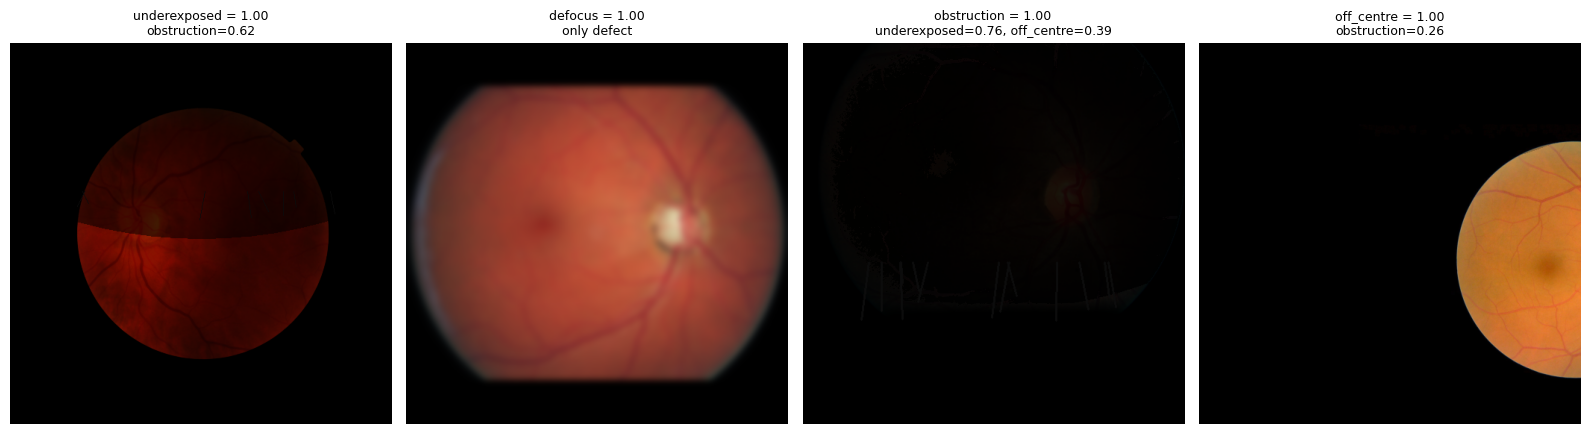

In [10]:
# pick the most severe example of each defect and look at it
fig, axes = plt.subplots(1, len(DEFECTS), figsize=(4 * len(DEFECTS), 4.4))
for ax, d in zip(axes, DEFECTS):
    row = deg.sort_values(d, ascending=False).iloc[0]
    img = cv2.imread(str(DEGRADED / row.filename))
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    others = [f"{o}={row[o]:.2f}" for o in DEFECTS if o != d and row[o] > 0]
    ax.set_title(f"{d} = {row[d]:.2f}\n{', '.join(others) or 'only defect'}",
                 fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURES / "degradation_examples.png", dpi=150)
plt.show()

In [11]:
# no source image may appear in more than one split later - check patients
print(f"source patients: {deg.patient_id.nunique():,}")
print(f"images per patient: {len(deg) / deg.patient_id.nunique():.1f}")

# label distribution: each defect should be non-zero in roughly
# (1..3 chosen from 4) x N_VARIANTS / (N_VARIANTS + 1) of rows
for d in DEFECTS:
    nz = (deg[d] > 0).mean()
    print(f"{d:14s} non-zero in {nz:.1%} of rows, "
          f"mean severity when present {deg.loc[deg[d] > 0, d].mean():.2f}")

source patients: 4,365
images per patient: 7.8
underexposed   non-zero in 40.2% of rows, mean severity when present 0.62
defocus        non-zero in 39.7% of rows, mean severity when present 0.63
obstruction    non-zero in 40.2% of rows, mean severity when present 0.62
off_centre     non-zero in 39.9% of rows, mean severity when present 0.62


In [12]:
ext = pd.read_csv(EXTERNAL / "manifest_external_512.csv")
# the external manifest now holds four datasets including FQS; only DeepDRiD
# carries the Clarity / Artifact sub-scores this comparison needs
dd = ext[ext.dataset == "deepdrid"].dropna(subset=["clarity", "artifact"])
print(f"{len(dd):,} DeepDRiD images with real sub-scores")


def feat_of(path):
    img = cv2.imread(str(path))
    return features(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))


# real: does low Clarity go with low lap_var?
real = pd.DataFrame([feat_of(EXTERNAL / "external_512" / f)
                     for f in tqdm(dd.filename.head(400), desc="real")])
real["clarity"] = dd.clarity.head(400).values
real["artifact"] = dd.artifact.head(400).values

# synthetic: does high defocus severity go with low lap_var?
samp = deg.sample(400, random_state=SEED)
syn = pd.DataFrame([feat_of(DEGRADED / f)
                    for f in tqdm(samp.filename, desc="synthetic")])
syn["defocus"] = samp.defocus.values
syn["obstruction"] = samp.obstruction.values

print("\nREAL     corr(lap_var, clarity)      = "
      f"{real.lap_var.corr(real.clarity):+.3f}   (expect positive)")
print("SYNTH    corr(lap_var, defocus)      = "
      f"{syn.lap_var.corr(syn.defocus):+.3f}   (expect negative)")
print("\nREAL     corr(illum_cv, artifact)    = "
      f"{real.illum_cv.corr(real.artifact):+.3f}   (expect positive)")
print("SYNTH    corr(illum_cv, obstruction) = "
      f"{syn.illum_cv.corr(syn.obstruction):+.3f}   (expect positive)")

1,600 DeepDRiD images with real sub-scores


real:   0%|          | 0/400 [00:00<?, ?it/s]

synthetic:   0%|          | 0/400 [00:00<?, ?it/s]


REAL     corr(lap_var, clarity)      = +0.120   (expect positive)
SYNTH    corr(lap_var, defocus)      = -0.443   (expect negative)

REAL     corr(illum_cv, artifact)    = +0.379   (expect positive)
SYNTH    corr(illum_cv, obstruction) = +0.641   (expect positive)


In [13]:
for junk in [".virtual_documents"]:
    shutil.rmtree(WORK / junk, ignore_errors=True)

print(sorted(p.name for p in WORK.iterdir()))
print(f"{len(list(DEGRADED.iterdir())):,} degraded images")
!du -sh {DEGRADED}
!df -h /kaggle/working

['__notebook__.ipynb', 'degraded', 'figures', 'manifest_degraded.csv']
33,990 degraded images
5.8G	/kaggle/working/degraded
Filesystem      Size  Used Avail Use% Mounted on
/dev/loop2       20G  5.8G   14G  30% /kaggle/working
